In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from scipy.signal import correlate2d, convolve2d

camera = data.camera().astype(np.uint8)
moon = data.moon().astype(np.uint8)


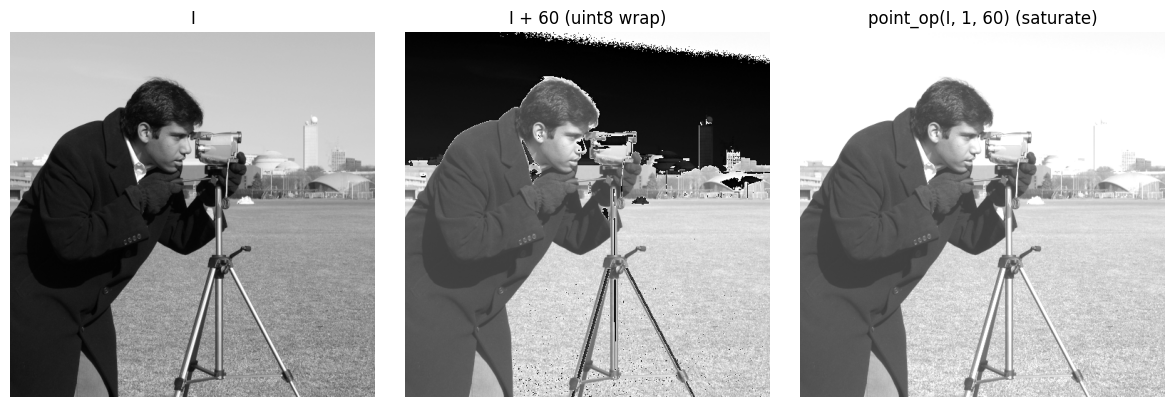

In [2]:
def linear_map(img, lo, hi):
    if hi <= lo:
        raise ValueError("hi must be greater than lo")
    out = (img.astype(np.float32) - lo) * (255.0 / (hi - lo))
    return np.clip(out, 0, 255).astype(np.uint8)

def point_op(img, a, b):
    return np.clip(a * img.astype(np.float32) + b, 0, 255).astype(np.uint8)

I = camera
wrapped = (I + 60)
saturated = point_op(I, 1, 60)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, im, title in zip(ax, [I, wrapped, saturated], ["I", "I + 60 (uint8 wrap)", "point_op(I, 1, 60) (saturate)"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(title); a.axis("off")
plt.tight_layout()


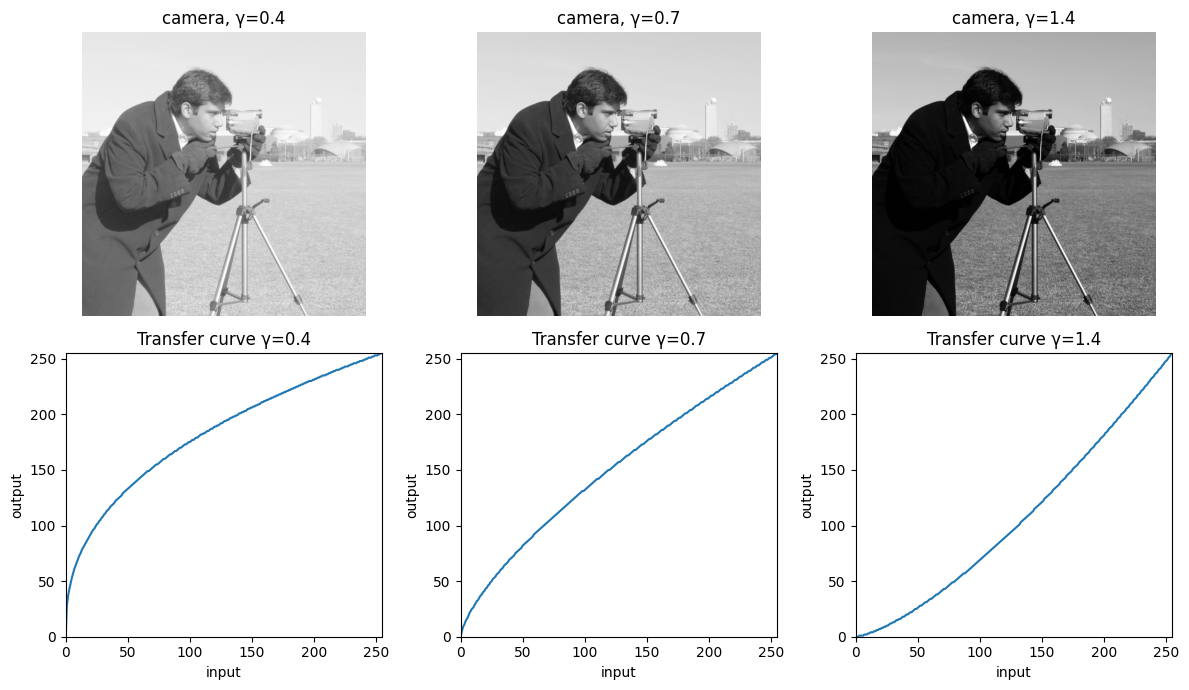

In [3]:
def gamma_lut(g):
    x = np.arange(256, dtype=np.float32) / 255.0
    return np.clip(np.round(255 * x**g), 0, 255).astype(np.uint8)

gammas = [0.4, 0.7, 1.4]
fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for j, g in enumerate(gammas):
    ax[0,j].imshow(gamma_lut(g)[camera], cmap="gray", vmin=0, vmax=255)
    ax[0,j].set_title(f"camera, γ={g}"); ax[0,j].axis("off")
    ax[1,j].plot(np.arange(256), gamma_lut(g)); ax[1,j].set_title(f"Transfer curve γ={g}")
    ax[1,j].set(xlim=(0,255), ylim=(0,255), xlabel="input", ylabel="output")
plt.tight_layout()


In [4]:
lo, hi = np.percentile(moon, [1, 99])
moon_pct = linear_map(moon, lo, hi)
moon_eq = cv2.equalizeHist(moon)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(moon)


def my_equalize(img):
    hist = np.bincount(img.ravel(), minlength=256)
    cdf = np.cumsum(hist)
    occupied = cdf[hist > 0]
    cdf_min = occupied[0]
    denom = img.size - cdf_min
    if denom <= 0:
        return img.copy()
    lut = np.clip(np.round((cdf - cdf_min) * 255.0 / denom), 0, 255).astype(np.uint8)
    return lut[img]

moon_my_eq = my_equalize(moon)
print("max |my_equalize - cv2.equalizeHist| =", np.abs(moon_my_eq.astype(int)-moon_eq.astype(int)).max())


max |my_equalize - cv2.equalizeHist| = 0


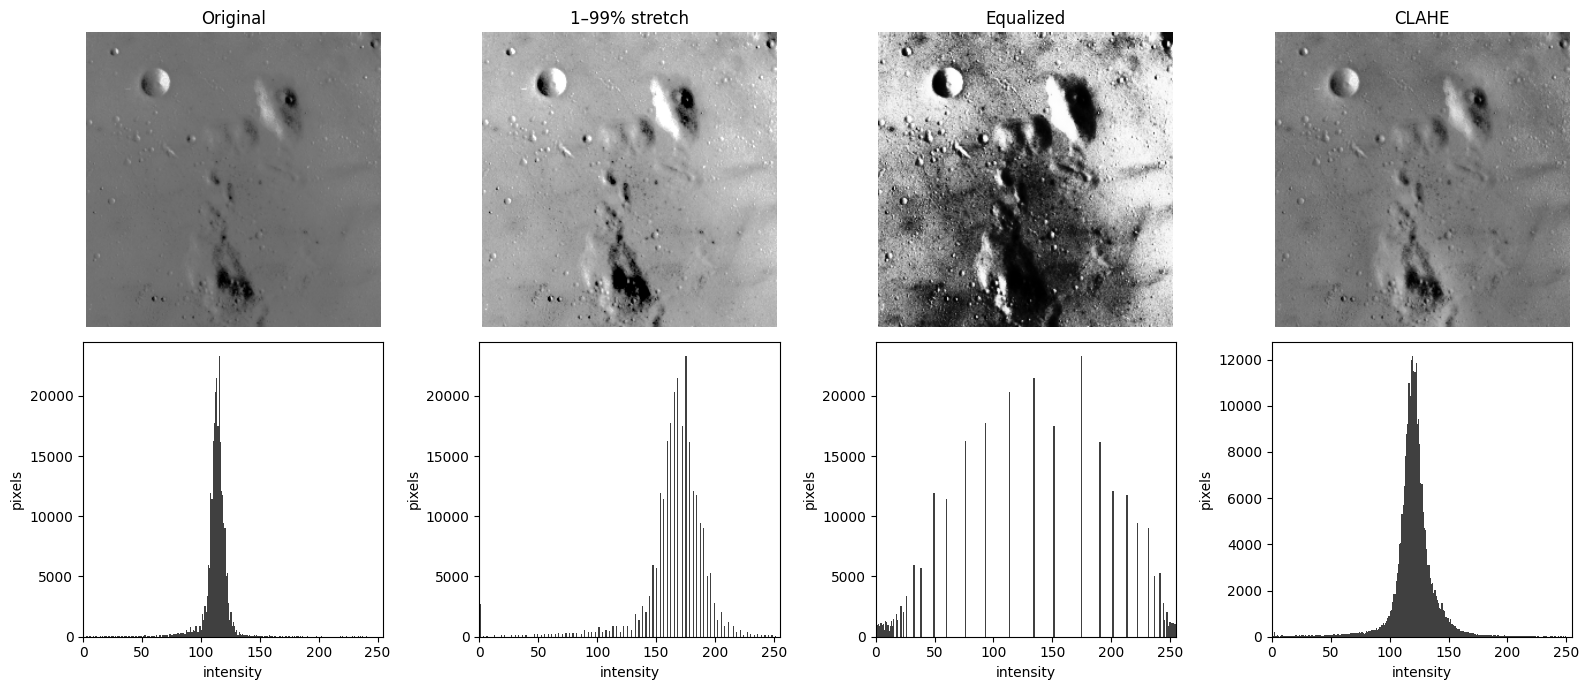

In [5]:
versions = [("Original", moon), ("1–99% stretch", moon_pct), ("Equalized", moon_eq), ("CLAHE", clahe)]
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for j, (name, im) in enumerate(versions):
    ax[0,j].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0,j].set_title(name); ax[0,j].axis("off")
    ax[1,j].hist(im.ravel(), bins=256, range=(0,256), color="0.25")
    ax[1,j].set(xlim=(0,255), xlabel="intensity", ylabel="pixels")
plt.tight_layout()


In [6]:
f = np.arange(1, 26, dtype=np.float32).reshape(5,5)
box = np.ones((3,3), dtype=np.float32) / 9
corr = correlate2d(f, box, mode="same", boundary="fill", fillvalue=0)
print("f=\n", f, "\ncorrelate2d output=\n", corr, "\ncenter=", corr[2,2])

k = np.zeros((3,3), dtype=np.float32); k[1,2] = 1
corr_shift = correlate2d(f, k, mode="same", boundary="fill")
conv_shift = convolve2d(f, k, mode="same", boundary="fill")


f=
 [[ 1.  2.  3.  4.  5.]
 [ 6.  7.  8.  9. 10.]
 [11. 12. 13. 14. 15.]
 [16. 17. 18. 19. 20.]
 [21. 22. 23. 24. 25.]] 
correlate2d output=
 [[ 1.7777778  3.         3.6666667  4.3333335  3.1111112]
 [ 4.3333335  7.         8.         9.         6.3333335]
 [ 7.6666665 12.        13.        13.999999   9.666667 ]
 [11.        17.        17.999998  19.        13.       ]
 [ 8.444445  13.        13.666667  14.333334   9.777778 ]] 
center= 13.0


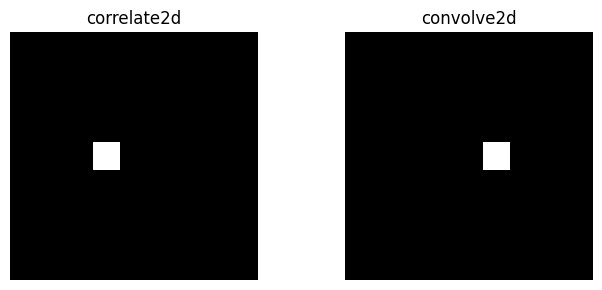

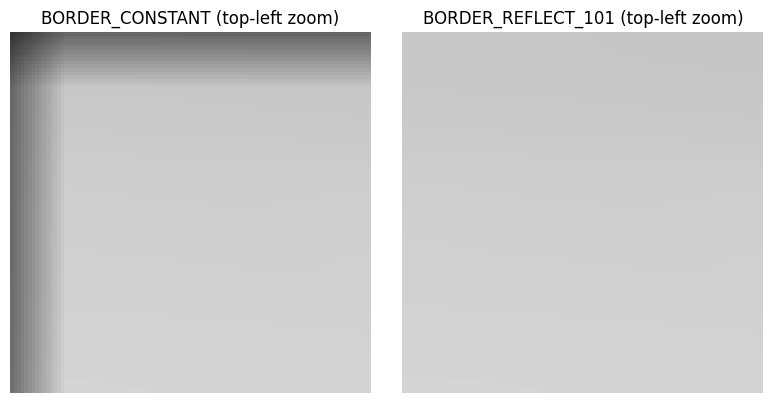

In [7]:
impulse = np.zeros((9,9), dtype=np.float32); impulse[4,4] = 90
k = np.zeros((3,3), dtype=np.float32); k[1,2] = 1
fig, ax = plt.subplots(1,2, figsize=(7,3))
for a, im, name in zip(ax, [correlate2d(impulse,k,mode="same"), convolve2d(impulse,k,mode="same")], ["correlate2d", "convolve2d"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=90); a.set_title(name); a.axis("off")
plt.tight_layout()

blur_const = cv2.blur(camera, (31,31), borderType=cv2.BORDER_CONSTANT)
blur_reflect = cv2.blur(camera, (31,31), borderType=cv2.BORDER_REFLECT_101)
fig, ax = plt.subplots(1,2,figsize=(8,4))
for a, im, name in zip(ax,[blur_const,blur_reflect],["BORDER_CONSTANT","BORDER_REFLECT_101"]):
    a.imshow(im[:100,:100], cmap="gray", vmin=0, vmax=255); a.set_title(name+" (top-left zoom)"); a.axis("off")
plt.tight_layout()


In [8]:
rng = np.random.default_rng(23)
I = camera.copy()
damaged = np.clip(I.astype(np.float32) + 35 + rng.normal(0, 7, I.shape), 0, 255).astype(np.uint8)

def psnr(reference, estimate):
    mse = np.mean((reference.astype(np.float32)-estimate.astype(np.float32))**2)
    return float("inf") if mse == 0 else 10*np.log10(255**2/mse)

def rescue(img):

    unbright = np.clip(img.astype(np.int16)-35, 0, 255).astype(np.uint8)
    return cv2.medianBlur(unbright, 3)

naive = cv2.equalizeHist(damaged)
restored = rescue(damaged)
swapped = np.clip(cv2.medianBlur(damaged,3).astype(np.int16)-35,0,255).astype(np.uint8)
print(f"equalizeHist PSNR: {psnr(I,naive):.2f} dB")
print(f"rescue PSNR: {psnr(I,restored):.2f} dB")
print(f"swapped order (median then subtract) PSNR: {psnr(I,swapped):.2f} dB")


equalizeHist PSNR: 21.29 dB
rescue PSNR: 29.52 dB
swapped order (median then subtract) PSNR: 29.52 dB


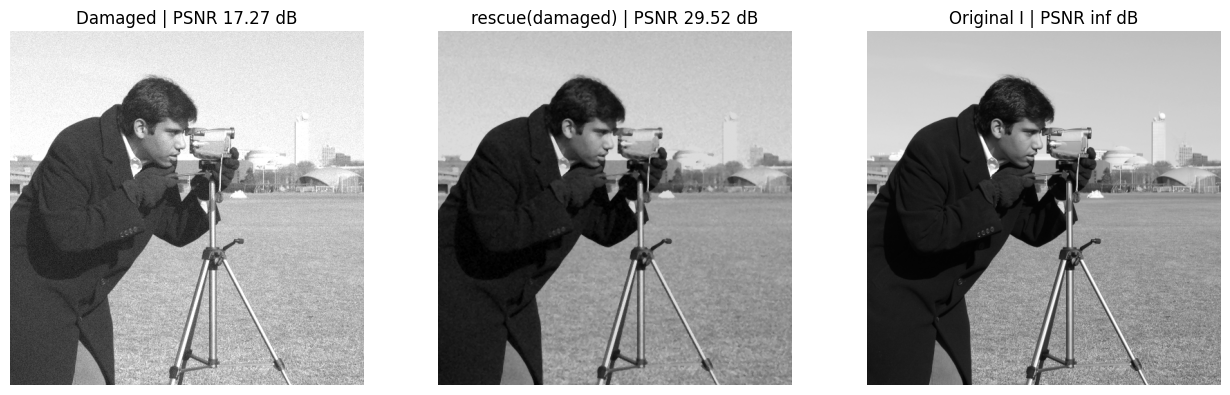

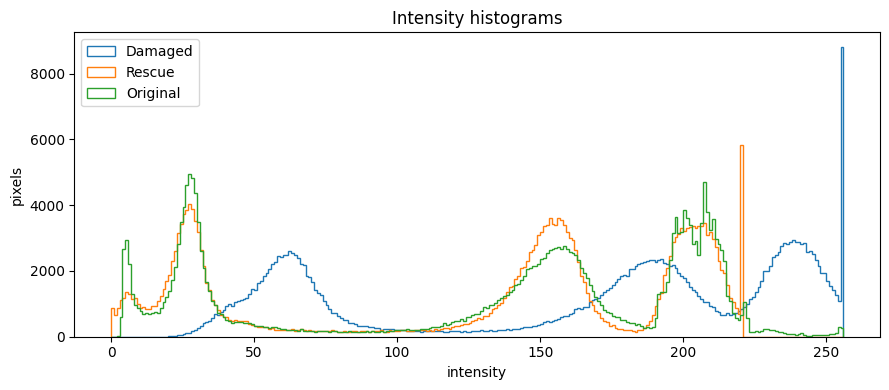

In [9]:
fig, ax = plt.subplots(1,3,figsize=(13,4))
for a, im, name in zip(ax,[damaged,restored,I],["Damaged","rescue(damaged)","Original I"]):
    a.imshow(im,cmap="gray",vmin=0,vmax=255); a.set_title(f"{name} | PSNR {psnr(I,im):.2f} dB"); a.axis("off")
plt.tight_layout()
fig, ax = plt.subplots(figsize=(9,4))
for im,name in zip([damaged,restored,I],["Damaged","Rescue","Original"]): ax.hist(im.ravel(),bins=256,range=(0,256),histtype="step",label=name)
ax.set(xlabel="intensity",ylabel="pixels",title="Intensity histograms"); ax.legend(); plt.tight_layout()


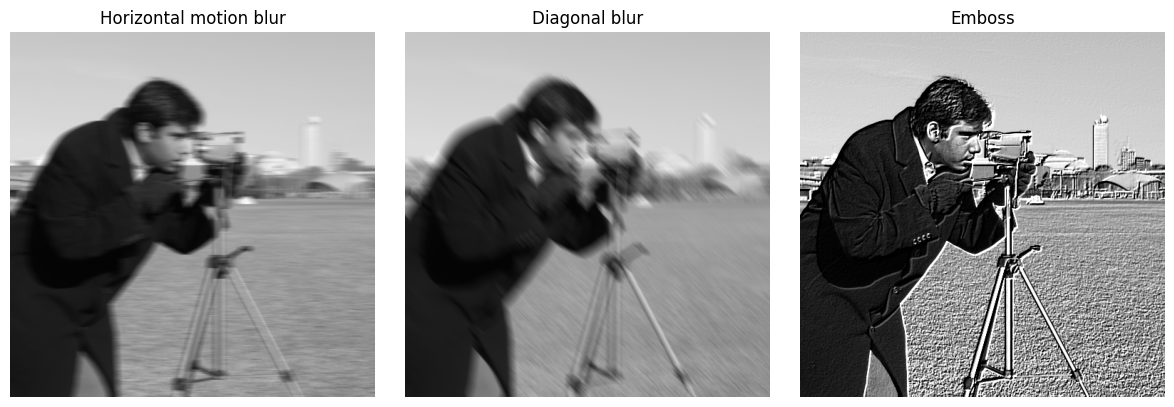

In [10]:
motion = np.zeros((15,15), dtype=np.float32); motion[7,:] = 1/15
motion_blur = cv2.filter2D(camera, -1, motion, borderType=cv2.BORDER_REFLECT_101)
diagonal = np.eye(15, dtype=np.float32)/15
diagonal_blur = cv2.filter2D(camera, -1, diagonal, borderType=cv2.BORDER_REFLECT_101)
emboss_kernel = np.array([[-2,-1,0],[-1,1,1],[0,1,2]], dtype=np.float32)
emboss = cv2.filter2D(camera, -1, emboss_kernel, borderType=cv2.BORDER_REFLECT_101)
fig, ax = plt.subplots(1,3,figsize=(12,4))
for a,im,name in zip(ax,[motion_blur,diagonal_blur,emboss],["Horizontal motion blur","Diagonal blur","Emboss"]):
    a.imshow(im,cmap="gray",vmin=0,vmax=255); a.set_title(name); a.axis("off")
plt.tight_layout()
